# 05 — Control 2: compensated SGD

### How to read this notebook
Run cells top to bottom. Each Markdown cell states the question and expected result **before** the code. The printed and plotted numbers are measurements, not claims made in advance. The shared functions live in `src/experiment.py`. Open Jupyter from the project root so imports work.

## Why this control?

Inverse initialization matches initial functions, but plain SGD updates the **effective** complex weights $V_c=\alpha W_c^{(\alpha)}$ by $-\eta\alpha^2G^\top X_c$. To match the reference effective update, use a complex-column learning rate $\eta_c=\eta/\alpha^2$. Leave the simple column and second layer at $\eta$.

The shared training function implements this by dividing **only** `fc1.weight.grad[:, 1:3]` by $\alpha^2$ before the optimizer step. This requires plain SGD without momentum, weight decay, clipping, or other parameter-coupled transformations.

In [1]:
from pathlib import Path
import os
import sys

# Resolve this experiment before imports and relative result paths.
ROOT = Path.cwd()
if not (ROOT / 'src' / 'experiment.py').is_file():
    ROOT = ROOT / 'experiment_1'
assert (ROOT / 'src' / 'experiment.py').is_file(), 'Start Jupyter in SimpBias or experiment_1.'
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.experiment import *
import torch
import numpy as np
import matplotlib.pyplot as plt
print('PyTorch:', torch.__version__)

PyTorch: 2.14.1+cpu


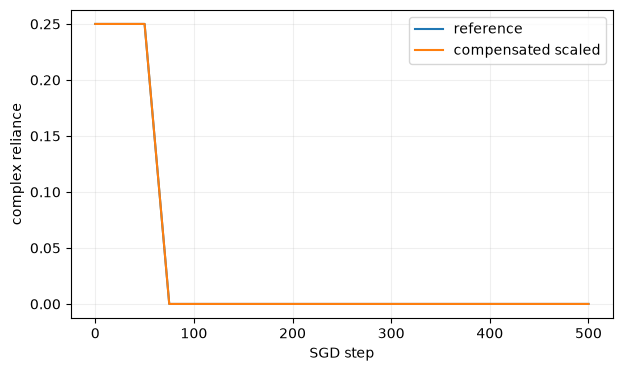

Max final logit difference: 4.76837158203125e-07
Reference: {'step': 500, 'loss': 0.020811930298805237, 'accuracy': 1.0, 'complex_reliance': 0.0, 'simple_flip_rate': 1.0, 'complex_flip_rate': 0.0, 'simple_probability_change': 0.8917499780654907, 'complex_probability_change': 0.07035654038190842}
Compensated: {'step': 500, 'loss': 0.020811930298805237, 'accuracy': 1.0, 'complex_reliance': 0.0, 'simple_flip_rate': 1.0, 'complex_flip_rate': 0.0, 'simple_probability_change': 0.8917499780654907, 'complex_probability_change': 0.07035654783248901}


In [2]:
alpha=5
x1,y=make_data(1024,11,1)
xa,_=make_data(1024,11,alpha)
ref=make_model(42)
scaled=inverse_initialize(make_model(42),ref,alpha)
h1=train(ref,x1,y,steps=500,lr=0.03,alpha=1)
ha=train(scaled,xa,y,steps=500,lr=0.03,alpha=alpha,compensate=True)
# Compare all recorded metrics, not just the last checkpoint.
for r1, ra in zip(h1, ha):
    assert r1['step'] == ra['step']
    for key in r1:
        assert np.isclose(r1[key], ra[key], atol=1e-5, rtol=1e-4), (r1['step'], key)
plot_histories({'reference':h1,'compensated scaled':ha})
with torch.no_grad():
    diff=(ref(x1)-scaled(xa)).abs().max().item()
print('Max final logit difference:',diff)
print('Reference:',h1[-1])
print('Compensated:',ha[-1])
assert torch.allclose(ref(x1),scaled(xa),atol=1e-4,rtol=1e-4)
save_rows([{'experiment':'compensated_reference','alpha':1,**h1[-1]}, {'experiment':'compensated_scaled','alpha':alpha,**ha[-1]}],'results/05_compensated.csv')

## Interpretation

Matching trajectories are **expected mathematically** under the stated assumptions. This is a negative/sanity control, not an independent proof of why ordinary scaling changed feature reliance. If the check fails, investigate numerical precision or whether any training operation violates the assumptions.